<a href="https://colab.research.google.com/github/galih342/model_dan_pelatihan_model_Prediksi_kebakaran_hutan_dan_lahan/blob/main/Prediksi_kebakaran_hutan_dan_lahan_(karhutla)_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. IMPORT LIBRARY
import pandas as pd
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import os

# 2. BACA FILE LANGSUNG DARI COLAB RUNTIME
# Jalur default file yang di-upload langsung ke Colab adalah /content/
file_path = '/content/panel_eda_enriched_2012_2025.parquet'

# Catatan: Jika nama file yang Anda upload berbeda di panel kiri Colab,
# ganti 'panel_eda_enriched_2012_2025.parquet' sesuai nama file Anda.

print("Membaca dataset dari Colab runtime...")
df = pd.read_parquet(file_path)

# 3. FILTER WILAYAH & CEK SYARAT MINIMAL DATASET
prov_col = 'province' if 'province' in df.columns else 'provinsi'
df_kalteng = df[df[prov_col].isin(['Kalimantan Tengah', 'Central Kalimantan'])].copy()

# Hapus baris tanpa target
df_kalteng = df_kalteng.dropna(subset=['hotspot_count'])

print(f"Total Sampel Kalteng: {len(df_kalteng)}")
if len(df_kalteng) < 5000:
    print("Peringatan: Data Kalteng < 5000 baris. Menggunakan seluruh data Kalimantan agar lolos syarat UTS.")
    df_borneo = df[df[prov_col].str.contains('Kalimantan', case=False, na=False)].copy()
    df_borneo = df_borneo.dropna(subset=['hotspot_count'])
    df_data = df_borneo
else:
    df_data = df_kalteng

print(f"Total Sampel Final yang Digunakan: {len(df_data)} (Syarat UTS: >= 5000)")

# 4. PEMISAHAN FITUR (X) DAN TARGET (y)
y = df_data['hotspot_count'].values
X_df = df_data.select_dtypes(include=[np.number]).drop(columns=['hotspot_count'])
X_df = X_df.fillna(X_df.median()) # Isi missing value fitur dengan median
X = X_df.values

# 5. PEMBAGIAN TRAIN (70%), VALIDATION (15%), TEST (15%) -> Wajib UTS
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.15, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.1764, random_state=42)

# 6. NORMALISASI DATA (Standardization)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("\nData berhasil diproses dan siap dilatih!")
print(f"Bentuk X_train: {X_train_scaled.shape}")
print(f"Jumlah sampel Train: {len(X_train_scaled)}, Val: {len(X_val_scaled)}, Test: {len(X_test_scaled)}")

Membaca dataset dari Colab runtime...
Menggunakan kolom target: fire_count_lnh
Total Sampel Kalteng: 38808
Total Sampel Final yang Digunakan: 38808 (Syarat UTS: >= 5000)

Data berhasil diproses dan siap dilatih!
Bentuk X_train: (27167, 97)
Jumlah sampel Train: 27167, Val: 5819, Test: 5822


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
import matplotlib.pyplot as plt

# 1. ARSITEKTUR MLP REGRESI
model = Sequential([
    # Input Layer & Hidden Layer 1
    Dense(128, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    BatchNormalization(), # Teknik Optimasi (Syarat CPMK 3)
    Dropout(0.3),         # Teknik Regularisasi (Syarat CPMK 3)

    # Hidden Layer 2
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    # Hidden Layer 3
    Dense(32, activation='relu'),

    # Output Layer (1 Neuron untuk Regresi)
    Dense(1, activation='linear')
])

# 2. KOMPILASI MODEL (Menggunakan Adam Optimizer)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

# 3. PELATIHAN MODEL (Training)
print("\nMemulai proses belajar (Training)...")
history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=50,
    batch_size=64,
    verbose=1
)

# 4. EVALUASI AKHIR (Testing)
test_loss, test_mae = model.evaluate(X_test_scaled, y_test)
print(f"\nMean Absolute Error (MAE) pada Data Test: {test_mae:.2f}")

# 5. SIMPAN MODEL (Untuk dikumpulkan di GitHub/UAS)
model_path = '/content/drive/MyDrive/skripsi/models/mlp_karhutla.h5'
os.makedirs(os.path.dirname(model_path), exist_ok=True)
model.save(model_path)
print(f"Model tersimpan di: {model_path}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        12,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,681 (92.50 KB)

 Trainable params: 23,297 (91.00 KB)

 Non-trainable params: 384 (1.50 KB)


Memulai proses belajar (Training)...
Epoch 1/50
425/425 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - loss: 9565.9316 - mae: 13.3651 - val_loss: 1165.9504 - val_mae: 5.7626
Epoch 2/50
425/425 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 4747.6138 - mae: 13.9355 - val_loss: 5284.5200 - val_mae: 11.8922
Epoch 3/50
425/425 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 2903.0256 - mae: 14.2962 - val_loss: 9526.0742 - val_mae: 12.9616
Epoch 4/50
425/425 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 1883.3367 - mae: 13.1312 - val_loss: 8543.3604 - val_mae: 10.8767
Epoch 5/50
425/425 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - loss: 1447.4528 - mae: 10.7199 - val_loss: 6567.0376 - val_mae: 9.3726
Epoch 6/50
425/425 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 1266.2305 - mae: 9.0179 - val_loss: 11741.1719 - val_mae: 10.6581
Epoch 7/50
425/425 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 893.3810 - mae: 7.5075 - val_loss: 3393.1487 - val_mae: 8.0056
Epoch 8/50
425/425 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 816.8068 - mae: 7.1157 - 


Mean Absolute Error (MAE) pada Data Test: 3.99
Model tersimpan di: /content/drive/MyDrive/skripsi/models/mlp_karhutla.h5


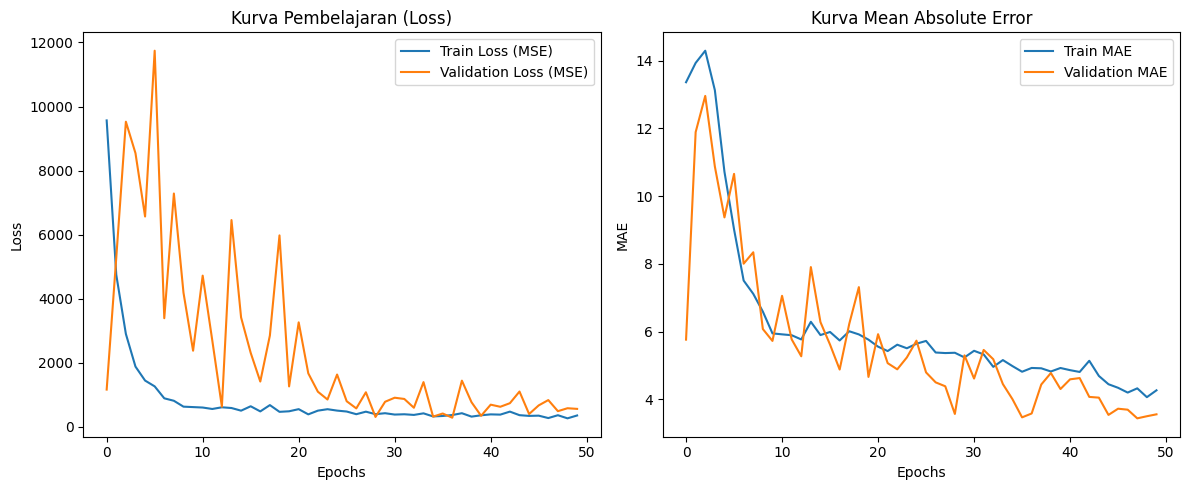

182/182 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


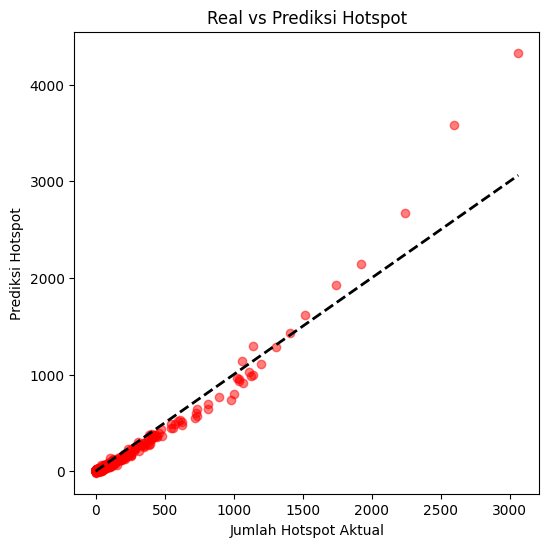

In [ ]:
# 1. KURVA LOSS (TRAINING VS VALIDATION)
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss (MSE)')
plt.plot(history.history['val_loss'], label='Validation Loss (MSE)')
plt.title('Kurva Pembelajaran (Loss)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# 2. KURVA MAE
plt.subplot(1, 2, 2)
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title('Kurva Mean Absolute Error')
plt.xlabel('Epochs')
plt.ylabel('MAE')
plt.legend()

plt.tight_layout()
plt.show()

# 3. SCATTER PLOT PREDIKSI VS AKTUAL PADA DATA TEST
y_pred = model.predict(X_test_scaled).flatten()

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='red')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--', lw=2)
plt.title('Real vs Prediksi Hotspot')
plt.xlabel('Jumlah Hotspot Aktual')
plt.ylabel('Prediksi Hotspot')
plt.show()